## 1. Import Required Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

from sklearn.ensemble import (
    StackingClassifier,
    AdaBoostClassifier,
    VotingClassifier
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

## 2. Load and Explore the Dataset

In [2]:
data = load_breast_cancer()

X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target)

print("Dataset: Breast Cancer Wisconsin")
print("Total samples:", X.shape[0])
print("Total features:", X.shape[1])
print("Target classes:", data.target_names)

display(X.head())

print("\nClass distribution:")
print(y.value_counts().rename(index={0: data.target_names[0], 1: data.target_names[1]}))

Dataset: Breast Cancer Wisconsin
Total samples: 569
Total features: 30
Target classes: ['malignant' 'benign']


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678



Class distribution:
benign       357
malignant    212
Name: count, dtype: int64


## 3. Split the Dataset

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 455
Testing samples: 114


## 4. Define Base Classifiers

In [4]:
def create_base_models():
    return {
        "Logistic Regression": make_pipeline(
            StandardScaler(),
            LogisticRegression(max_iter=5000)
        ),
        "Decision Tree": DecisionTreeClassifier(random_state=42),
        "KNN": make_pipeline(
            StandardScaler(),
            KNeighborsClassifier(n_neighbors=5)
        ),
        "SVM": make_pipeline(
            StandardScaler(),
            SVC(kernel="linear", probability=True, random_state=42)
        )
    }

base_models = create_base_models()

## 5. Define the Evaluation Function

In [5]:
results = []
all_predictions = {}
all_models = {}

def evaluate_model(name, model, X_test, y_test):
    y_pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

    all_predictions[name] = y_pred
    all_models[name] = model

    print("=" * 60)
    print("MODEL:", name)
    print("=" * 60)
    print("Accuracy :", round(accuracy, 4))
    print("Precision:", round(precision, 4))
    print("Recall   :", round(recall, 4))
    print("F1 Score :", round(f1, 4))
    print("\nClassification Report:")
    print(classification_report(
        y_test,
        y_pred,
        target_names=data.target_names,
        zero_division=0
    ))

    return y_pred

## 6. Train and Evaluate Individual Base Classifiers

In [6]:
for name, model in base_models.items():
    model.fit(X_train, y_train)
    evaluate_model(name, model, X_test, y_test)

MODEL: Logistic Regression
Accuracy : 0.9825
Precision: 0.9861
Recall   : 0.9861
F1 Score : 0.9861

Classification Report:
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114

MODEL: Decision Tree
Accuracy : 0.9123
Precision: 0.9559
Recall   : 0.9028
F1 Score : 0.9286

Classification Report:
              precision    recall  f1-score   support

   malignant       0.85      0.93      0.89        42
      benign       0.96      0.90      0.93        72

    accuracy                           0.91       114
   macro avg       0.90      0.92      0.91       114
weighted avg       0.92      0.91      0.91       114

MODEL: KNN
Accuracy : 0.9561
Precision: 0.9589
Recall   : 0.9722
F1 Score : 0.9655

Classification Report:

## 7. Implement Stacking Ensemble

In [7]:
stacking_estimators = [
    (
        "lr",
        make_pipeline(
            StandardScaler(),
            LogisticRegression(max_iter=5000)
        )
    ),
    (
        "dt",
        DecisionTreeClassifier(random_state=42)
    ),
    (
        "knn",
        make_pipeline(
            StandardScaler(),
            KNeighborsClassifier(n_neighbors=5)
        )
    ),
    (
        "svm",
        make_pipeline(
            StandardScaler(),
            SVC(kernel="linear", probability=True, random_state=42)
        )
    )
]

meta_classifier = LogisticRegression(max_iter=5000)

stacking_model = StackingClassifier(
    estimators=stacking_estimators,
    final_estimator=meta_classifier,
    cv=5,
    stack_method="predict_proba"
)

stacking_model.fit(X_train, y_train)

evaluate_model(
    "Stacking Classifier",
    stacking_model,
    X_test,
    y_test
)

MODEL: Stacking Classifier
Accuracy : 0.9825
Precision: 0.9861
Recall   : 0.9861
F1 Score : 0.9861

Classification Report:
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



array([0, 1, 0, 1, 0, 1, 1, 0, 0, 0, 1, 0, 1, 0, 0, 1, 0, 1, 1, 1, 0, 0,
       1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 0, 1, 1, 1, 0,
       0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 0, 0,
       1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 1,
       1, 1, 1, 1, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0,
       1, 0, 1, 1])

## 8. Implement AdaBoost Ensemble

In [8]:
weak_learner = DecisionTreeClassifier(
    max_depth=1,
    random_state=42
)

adaboost_model = AdaBoostClassifier(
    estimator=weak_learner,
    n_estimators=100,
    learning_rate=1.0,
    random_state=42
)

adaboost_model.fit(X_train, y_train)

evaluate_model(
    "AdaBoost Classifier",
    adaboost_model,
    X_test,
    y_test
)

MODEL: AdaBoost Classifier
Accuracy : 0.9561
Precision: 0.9467
Recall   : 0.9861
F1 Score : 0.966

Classification Report:
              precision    recall  f1-score   support

   malignant       0.97      0.90      0.94        42
      benign       0.95      0.99      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



array([0, 1, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 1, 0, 0, 1, 1, 1, 1, 1, 0, 0,
       1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 0,
       0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 0, 1,
       1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0,
       1, 0, 1, 1])

## 9. Implement Voting Ensemble

In [9]:
voting_estimators = [
    (
        "lr",
        make_pipeline(
            StandardScaler(),
            LogisticRegression(max_iter=5000)
        )
    ),
    (
        "dt",
        DecisionTreeClassifier(random_state=42)
    ),
    (
        "knn",
        make_pipeline(
            StandardScaler(),
            KNeighborsClassifier(n_neighbors=5)
        )
    ),
    (
        "svm",
        make_pipeline(
            StandardScaler(),
            SVC(kernel="linear", probability=True, random_state=42)
        )
    )
]

voting_model = VotingClassifier(
    estimators=voting_estimators,
    voting="hard"
)

voting_model.fit(X_train, y_train)

evaluate_model(
    "Voting Classifier",
    voting_model,
    X_test,
    y_test
)

MODEL: Voting Classifier
Accuracy : 0.9737
Precision: 0.9859
Recall   : 0.9722
F1 Score : 0.979

Classification Report:
              precision    recall  f1-score   support

   malignant       0.95      0.98      0.96        42
      benign       0.99      0.97      0.98        72

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114



array([0, 1, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 1, 0, 0, 1, 0, 1, 1, 1, 0, 0,
       1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 0, 1, 1, 1, 0,
       0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 0, 0,
       1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 1,
       1, 1, 1, 1, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0,
       1, 0, 1, 1])

## 10. Performance Comparison

In [10]:
results_df = pd.DataFrame(results)

display(
    results_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1 Score": "{:.4f}"
    })
)

results_df.to_csv("ensemble_performance_comparison.csv", index=False)

print("Performance comparison saved to ensemble_performance_comparison.csv")

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.9825,0.9861,0.9861,0.9861
1,Decision Tree,0.9123,0.9559,0.9028,0.9286
2,KNN,0.9561,0.9589,0.9722,0.9655
3,SVM,0.9737,0.9859,0.9722,0.9790
4,Stacking Classifier,0.9825,0.9861,0.9861,0.9861
5,AdaBoost Classifier,0.9561,0.9467,0.9861,0.9660
6,Voting Classifier,0.9737,0.9859,0.9722,0.9790


Performance comparison saved to ensemble_performance_comparison.csv


## 11. Visualize Performance Metrics

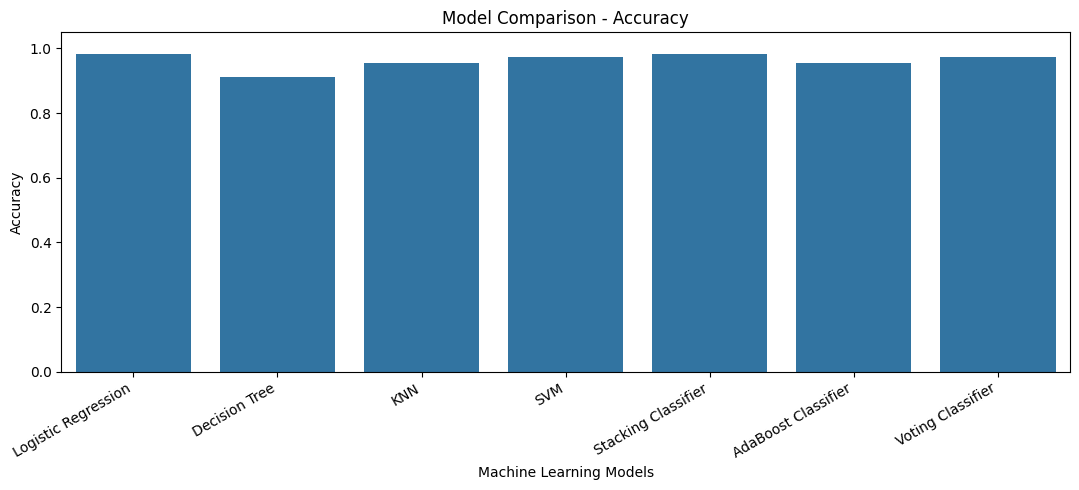

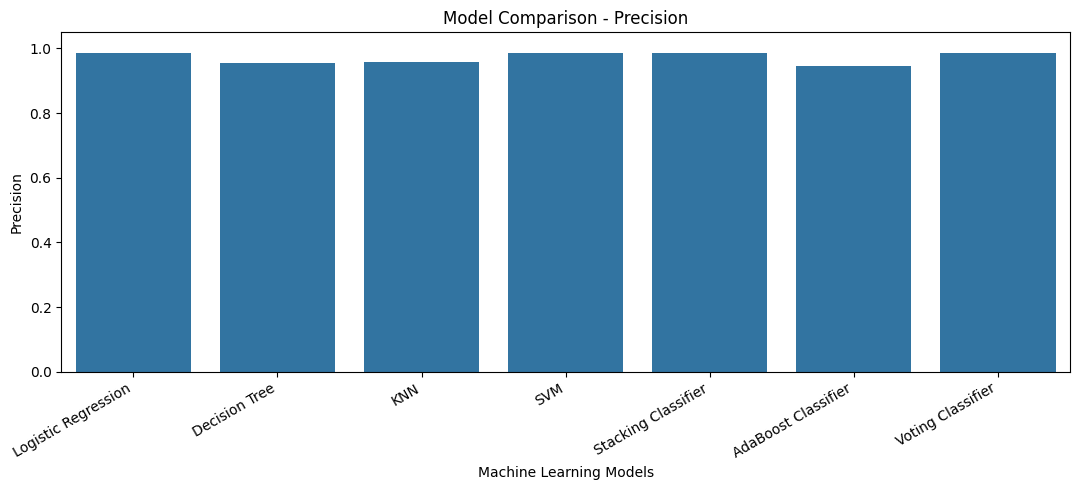

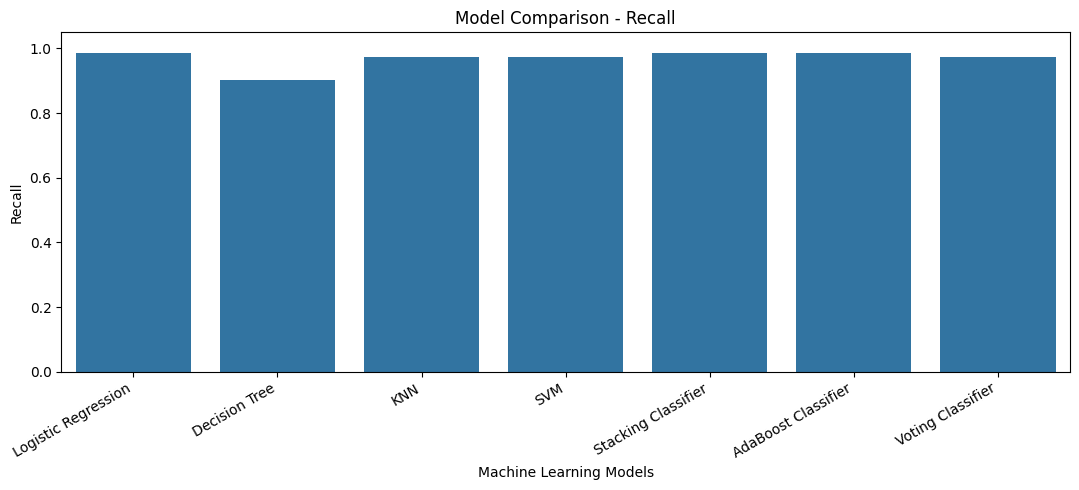

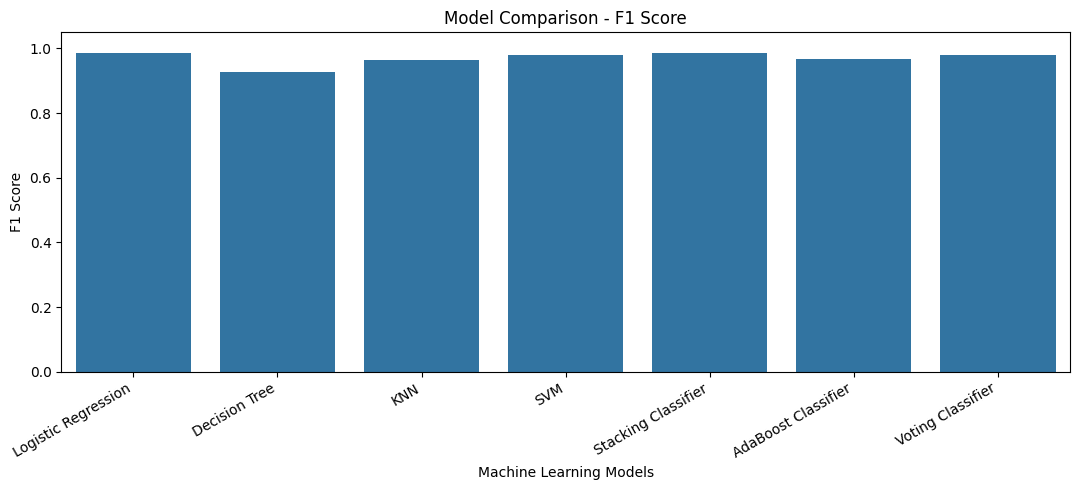

In [11]:
metrics = ["Accuracy", "Precision", "Recall", "F1 Score"]

for metric in metrics:
    plt.figure(figsize=(11, 5))
    sns.barplot(data=results_df, x="Model", y=metric)
    plt.title("Model Comparison - " + metric)
    plt.xlabel("Machine Learning Models")
    plt.ylabel(metric)
    plt.xticks(rotation=30, ha="right")
    plt.ylim(0, 1.05)
    plt.tight_layout()
    plt.show()

## 12. Confusion Matrices for All Seven Models

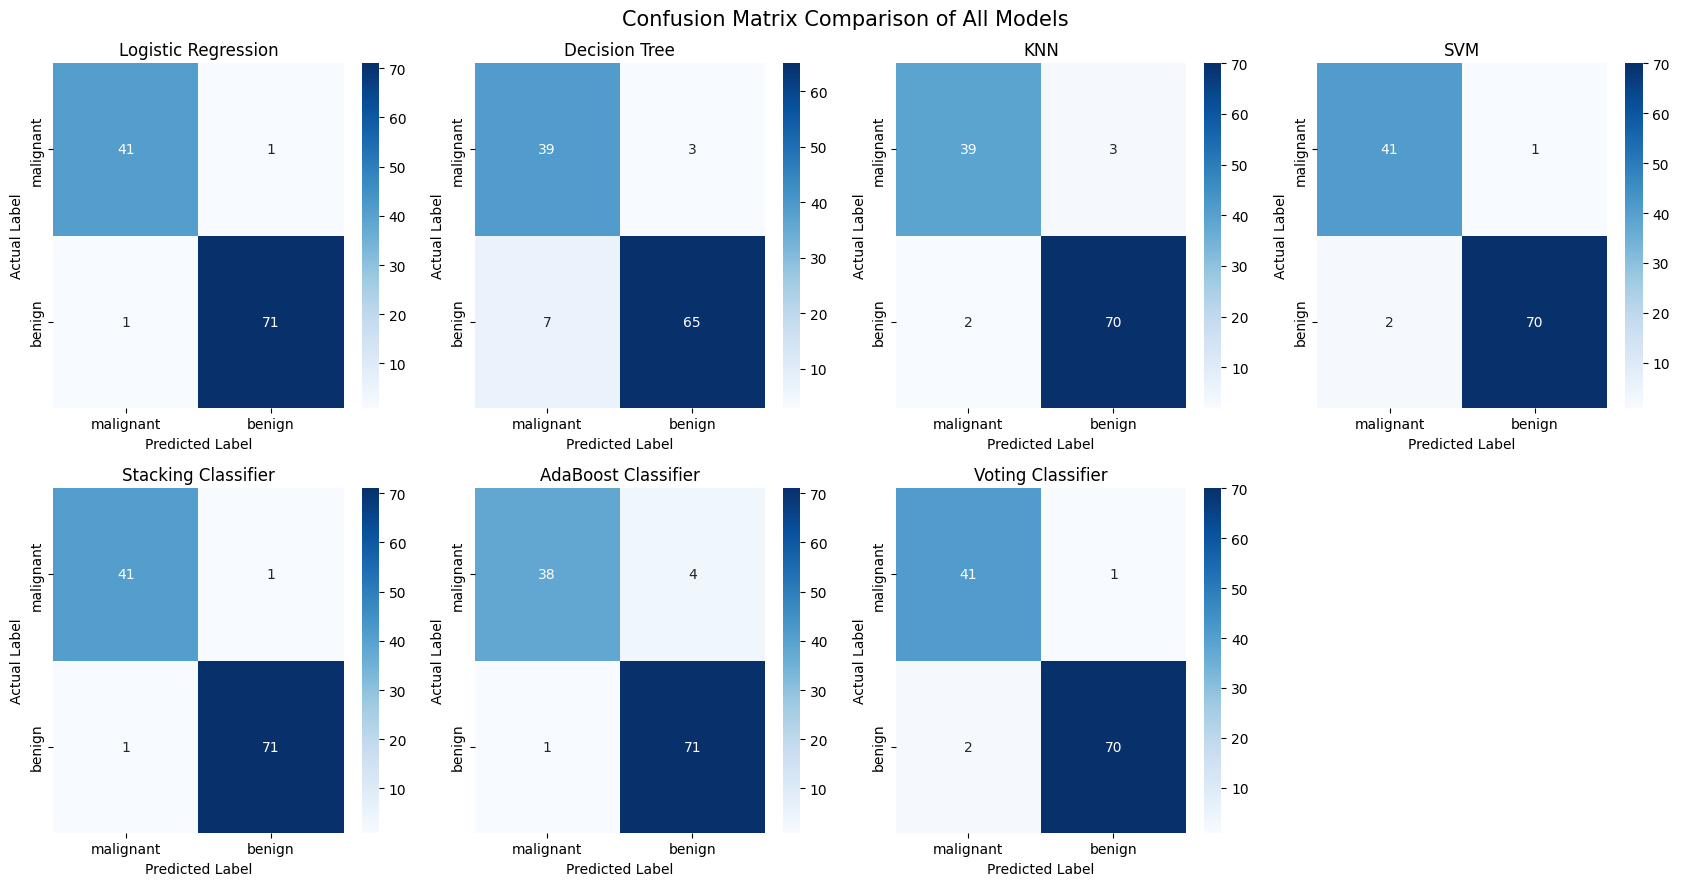

In [12]:
fig, axes = plt.subplots(2, 4, figsize=(17, 9))
axes = axes.flatten()

for i, (name, y_pred) in enumerate(all_predictions.items()):
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=data.target_names,
        yticklabels=data.target_names,
        ax=axes[i]
    )

    axes[i].set_title(name)
    axes[i].set_xlabel("Predicted Label")
    axes[i].set_ylabel("Actual Label")

axes[7].axis("off")

plt.suptitle("Confusion Matrix Comparison of All Models", fontsize=15)
plt.tight_layout()
plt.show()

## 13. Identify the Best Performing Model

In [13]:
best_model = results_df.loc[results_df["F1 Score"].idxmax()]

print("Best Model:", best_model["Model"])
print("Accuracy:", round(best_model["Accuracy"], 4))
print("Precision:", round(best_model["Precision"], 4))
print("Recall:", round(best_model["Recall"], 4))
print("F1 Score:", round(best_model["F1 Score"], 4))

Best Model: Logistic Regression
Accuracy: 0.9825
Precision: 0.9861
Recall: 0.9861
F1 Score: 0.9861


## 14. Findings and Observations

1. Individual classifiers may produce different classification results on the same dataset.
2. Stacking combines predictions from multiple base classifiers using a meta-classifier.
3. AdaBoost trains weak learners sequentially and gives greater emphasis to previously misclassified samples.
4. Voting combines predictions from multiple classifiers using majority voting.
5. Accuracy, precision, recall and F1 score provide different perspectives on model performance.
6. An ensemble model does not always outperform every individual classifier; performance depends on the dataset, model selection and parameter settings.

## 15. When to Use Each Ensemble Technique

| Ensemble technique | Suitable situation |
|---|---|
| Stacking | When diverse base classifiers are available and a meta-classifier can learn how to combine their predictions. |
| AdaBoost | When simple weak learners can be improved by focusing successively on difficult training examples. |
| Voting | When several reasonably strong and complementary classifiers are available and a straightforward combination is desired. |

## 16. Future Scope

1. Experiment with different base classifiers and meta-classifiers.
2. Apply hyperparameter tuning using GridSearchCV or RandomizedSearchCV.
3. Compare additional ensemble techniques such as Random Forest and Gradient Boosting.
4. Evaluate models using ROC-AUC and other classification metrics.
5. Test the models on larger and more diverse datasets.
6. Compare hard voting with soft voting.

## 17. Conclusion

The experiment implements and evaluates three ensemble learning techniques: Stacking, AdaBoost and Voting Classifiers. Four individual base classifiers are also trained to provide a comparison.

All models are evaluated using accuracy, precision, recall, F1 score and confusion matrices. The results help illustrate how ensemble techniques combine multiple classifiers and how their performance varies with the dataset and model configuration.

The best-performing model is identified using the F1 score. The experiment demonstrates that ensemble learning can improve classification performance in suitable situations, although no ensemble method is guaranteed to outperform every individual classifier.